# Hälsostudie - Del 1
## Namn: Ona Kotsolari

### Kurs: Pythonprogrammering och statistisk dataanalys

### Individuell uppgift – Hälsostudie

# Setup & Reproducerbarhet

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

np.random.seed(42)


df = pd.read_csv("data/health_study_dataset.csv")
display(df.head())
df.info()
print(df.isna().sum())



,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB
id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64


#  Beskrivande analys

In [2]:
stats_cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

df[stats_cols].agg(["mean", "median", "min", "max"])

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


# Visualiseringar

C:\Users\ona1k\AppData\Local\Temp\ipykernel_27352\2749766434.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


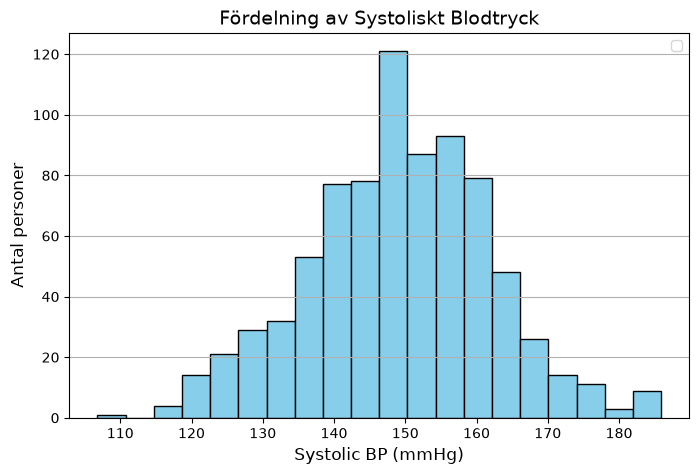

In [ ]:
# Skapa ett fönster för grafen 
fig, ax = plt.subplots(figsize=(8, 5))

# Rita ett histogram för systoliskt tryck
ax.hist(df["systolic_bp"], bins=20, color="skyblue", edgecolor="black")

# Titlar och taggar  
ax.set_title("Fördelning av Systoliskt Blodtryck", fontsize=14)
ax.set_xlabel("Systolic BP (mmHg)", fontsize=12)
ax.set_ylabel("Antal personer", fontsize=12)
ax.grid(True,axis="y")

# Visa diagrammet
plt.show()

# Diagram 1: Histogram för systoliskt blodtryck
## (systoliskt bp)

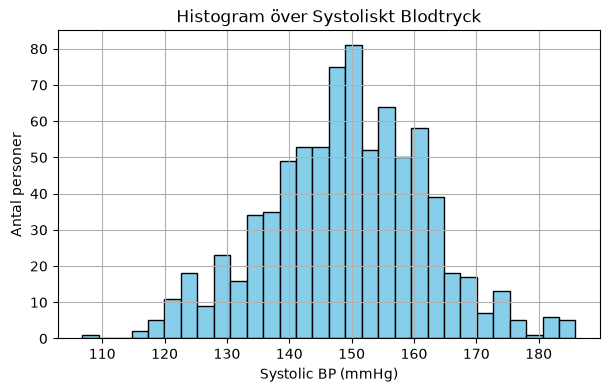

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["systolic_bp"], bins=30, color="skyblue", edgecolor="black")
ax.set_title("Histogram över Systoliskt Blodtryck")
ax.set_xlabel("Systolic BP (mmHg)")
ax.set_ylabel("Antal personer")
plt.grid()
plt.show()

# Diagram 2: Boxplot för vikt per kön!

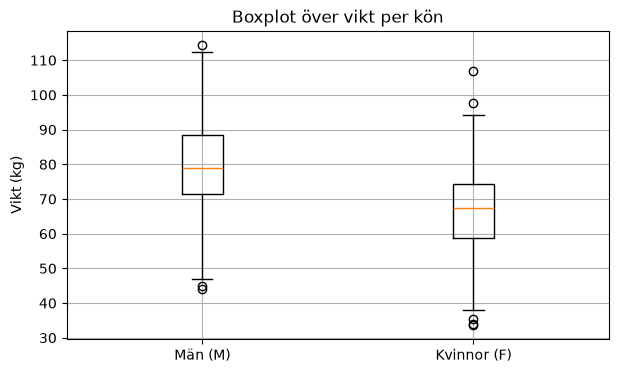

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))

# Vi delar upp vikten efter kön (M och K)
male_weights = df[df["sex"] == "M"]["weight"]
female_weights = df[df["sex"] == "F"]["weight"]

ax.boxplot([male_weights, female_weights], tick_labels=["Män (M)", "Kvinnor (F)"])
ax.set_title("Boxplot över vikt per kön")
ax.set_ylabel("Vikt (kg)")
plt.grid()
plt.show()

# Diagram 3: Stapeldiagrammet för andelen rökare.

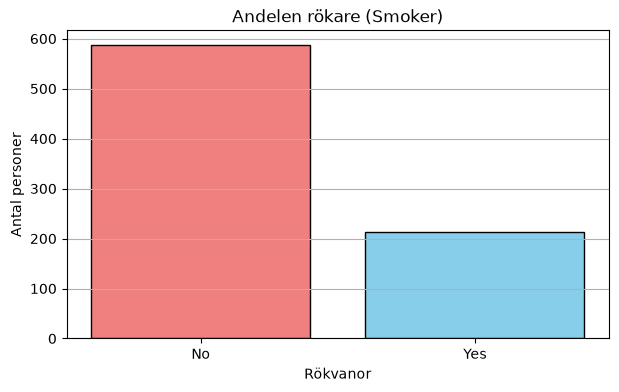

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

# Vi räknar hur många som är Ja och hur många som är Nej
smoker_counts = df["smoker"].value_counts()

ax.bar(smoker_counts.index, smoker_counts.values, color=["lightcoral", "skyblue"], edgecolor="black")
ax.set_title("Andelen rökare (Smoker)")
ax.set_xlabel("Rökvanor")
ax.set_ylabel("Antal personer")
plt.grid(True, axis="y")
plt.show()

# Simulering

In [7]:
# Jag hämtar viktdata från vår datauppsättning
data_weight = df["weight"].dropna()

# Hitta det sanna medelvärdet och standardavvikelsen 
true_mean = data_weight.mean()
true_std = data_weight.std()

print(f"Verkligt medelvärde: {true_mean:.2f}, Verklig std: {true_std:.2f}")

# Skapa en simulerad population på 1000 personer
simulated_weights = np.random.normal(true_mean, true_std, size=1000)

# Visa den statistiska beskrivningen med .describe() (precis som i exemplet)
pd.Series(simulated_weights).describe()

Verkligt medelvärde: 73.41, Verklig std: 13.69


count    1000.000000
mean       73.677560
std        13.400628
min        29.056066
25%        64.550689
50%        73.759240
75%        82.280150
max       126.137857
dtype: float64

In [8]:
# 1. Vi hittar den verkliga sannolikheten för sjukdom från vår datauppsättning
real_disease_prob = df["disease"].mean()
print(f"Verklig andel med sjukdom: {real_disease_prob:.4f} ({real_disease_prob * 100:.2f}%)")

# 2. Vi simulerar 1000 personer baserat på denna sannolikhet (med binomial)
n_simulations = 1000
simulated_disease = np.random.binomial(n=1, p=real_disease_prob, size=n_simulations)

# 3. Vi beräknar det simulerade förhållandet
simulated_prob = simulated_disease.mean()
print(f"Simulerad andel med sjukdom ({n_simulations} personer): {simulated_prob:.4f} ({simulated_prob * 100:.2f}%)")

Verklig andel med sjukdom: 0.0587 (5.88%)
Simulerad andel med sjukdom (1000 personer): 0.0580 (5.80%)


# Konfidensintervall

I denna del beräknas ett 95 % konfidensintervall för medelvärdet av systolic_bp. Två metoder används:

1. Normalapproximation
2. Bootstrap

Resultaten jämförs för att undersöka om metoderna ger liknande uppskattningar.

### Konfidensintervall - Normalapproximation


Vi beräknar ett 95 % konfidensintervall för medelvärdet av systolic_bp med hjälp av normalapproximation. 

Normalapproximation

- mean
- std
- standard error
- 1.96 × SE



In [9]:
bp = df["systolic_bp"]

mean_bp = bp.mean()
std_bp = bp.std(ddof=1)

n = len(bp)

se = std_bp / np.sqrt(n)

z = 1.96

lower_normal = mean_bp - z * se
upper_normal = mean_bp + z * se

print(f"Mean systolic_bp: {mean_bp:.2f}")
print(f"Normal KI: [{lower_normal:.2f}, {upper_normal:.2f}]")

Mean systolic_bp: 149.18
Normal KI: [148.29, 150.07]


### Tolkning av normalapproximation

Medelvärdet för systolic_bp är 149.18.

Det 95-procentiga konfidensintervallet är [148.29, 150.07].

Detta innebär att det verkliga medelvärdet uppskattas ligga inom detta intervall med 95 % konfidens.

### Konfidensintervall - Bootstrap
Vi använder bootstrap för att uppskatta konfidensintervallet utan att anta normalfördelning.

Bootstrap

- 5000 repetitioner
- sample with replacement
- mean
- percentiles 2.5 και 97.5

In [10]:
bootstrap_means = []

for _ in range(5000):
    sample = bp.sample(n=len(bp), replace=True)
    bootstrap_means.append(sample.mean())

lower_boot = np.percentile(bootstrap_means, 2.5)
upper_boot = np.percentile(bootstrap_means, 97.5)

print(f"Bootstrap KI: [{lower_boot:.2f}, {upper_boot:.2f}]")

Bootstrap KI: [148.33, 150.06]


# Histogram Bootstrap

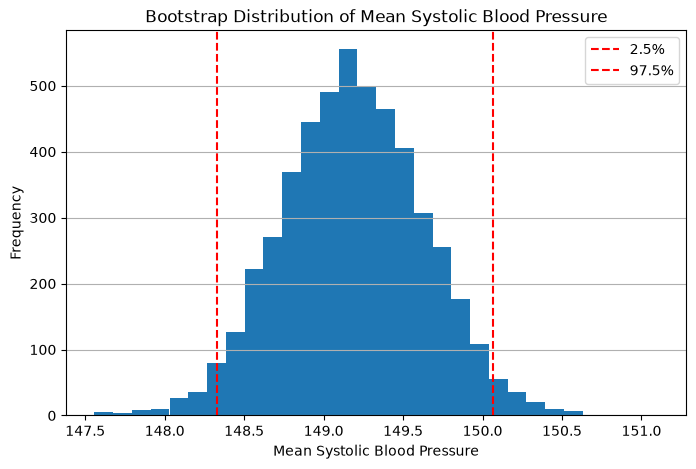

In [11]:

plt.figure(figsize=(8,5))

plt.hist(bootstrap_means, bins=30)

plt.axvline(lower_boot, color="red", linestyle="--", label="2.5%")
plt.axvline(upper_boot, color="red", linestyle="--", label="97.5%")

plt.title("Bootstrap Distribution of Mean Systolic Blood Pressure")
plt.xlabel("Mean Systolic Blood Pressure")
plt.ylabel("Frequency")
plt.grid(True, axis="y")

plt.legend()

plt.show()

### Tolkning av bootstrap

Bootstrap-metoden gav ett 95-procentigt konfidensintervall på [148.33, 150.06].

Intervallet är mycket likt resultatet från normalapproximationen.

## Jämförelse av metoder

Normalapproximationen gav intervallet [148.29, 150.07] medan bootstrap gav intervallet [148.33, 150.06].

Resultaten är nästan identiska, vilket tyder på att uppskattningen av medelvärdet är stabil.

Bootstrap kräver färre antaganden om datafördelningen, medan normalapproximationen bygger på statistiska antaganden om stickprovsfördelningen.

I detta fall leder båda metoderna till samma slutsats.

# Hypotesprövning & Power
 

# Hypotesprövning

- H0: Rökare och icke-rökare har samma genomsnittliga blodtryck.

- H1: Rökare har högre genomsnittligt blodtryck.

In [12]:
from scipy.stats import ttest_ind

smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
non_smokers = df[df["smoker"] == "No"]["systolic_bp"]

t_stat, p_value = ttest_ind(smokers, non_smokers)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

print(f"Mean smokers: {smokers.mean():.2f}")
print(f"Mean non-smokers: {non_smokers.mean():.2f}")

T-statistic: 0.4609
P-value: 0.6450
Mean smokers: 149.52
Mean non-smokers: 149.05


### Resultat
Resultatet är inte statistiskt signifikant.

P-värdet var 0.6450, vilket är större än 0.05.

Vi kan därför inte förkasta nollhypotesen.

Det finns inte tillräckligt med statistiskt stöd för att säga att rökare har högre genomsnittligt blodtryck än icke-rökare i detta dataset.

# Power Simulation

In [13]:
from scipy.stats import ttest_ind

n_simulations = 1000
significant_results = 0

for _ in range(n_simulations):

    group1 = np.random.normal(loc=130, scale=15, size=100)
    group2 = np.random.normal(loc=135, scale=15, size=100)

    _, p_value = ttest_ind(group1, group2)

    if p_value < 0.05:
        significant_results += 1

power = significant_results / n_simulations

print(f"Estimated power: {power:.3f}")

Estimated power: 0.650


# Diskussion


Två metoder användes för att beräkna ett 95 % konfidensintervall för systolic_bp: normalapproximation och bootstrap.

Resultaten från metoderna var mycket lika, vilket tyder på att skattningen av medelvärdet är stabil.

Hypotesprövningen jämförde blodtrycket mellan rökare och icke-rökare. P-värdet blev 0.645, vilket är större än 0.05. Därför kunde nollhypotesen inte förkastas och resultatet gav inget statistiskt stöd för att rökare har högre blodtryck i detta dataset.

Power-simuleringen gav ett uppskattat värde på cirka 0.64. Det innebär att testet upptäckte den verkliga skillnaden i ungefär 64 % av simuleringarna. Ett högre power-värde hade gett större sannolikhet att upptäcka skillnader när de faktiskt finns.

Bootstrap valdes också eftersom metoden kräver färre antaganden om normalfördelning än normalapproximationen.